In [1]:
# Cell 1: Import required libraries and load the dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Load the dataset
df = pd.read_csv("SVM-based Loan Predictor.csv")
print(f"Dataset successfully loaded! Shape: {df.shape}")
df.head()

Dataset successfully loaded! Shape: (614, 13)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [3]:
!pip install matplotlib seaborn pandas numpy scikit-learn joblib

In [4]:
# Cell 2: Handle missing values and categorical variables
# Drop identifier columns if present
if 'Loan_ID' in df.columns:
    df = df.drop(columns=['Loan_ID'])

# Fill missing numerical values with median, categorical with mode
for col in df.select_dtypes(include=[np.number]).columns:
    df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(include=['object']).columns:
    df[col] = df[col].fillna(df[col].mode()[0])

# Encode categorical variables (e.g., Gender, Married, Education, Property_Area)
df = pd.get_dummies(df, drop_first=True)

# Map target variable (Loan_Status: 'Y'/'N' to 1/0)
if 'Loan_Status_Y' in df.columns:
    df['Loan_Status'] = df['Loan_Status_Y']
    df = df.drop(columns=['Loan_Status_Y'])
elif 'Loan_Status' in df.columns and df['Loan_Status'].dtype == 'object':
    df['Loan_Status'] = df['Loan_Status'].map({'Y': 1, 'N': 0})

# Define features (X) and target (y)
X = df.drop(columns=['Loan_Status'])
y = df['Loan_Status']

print(f"Features shape: {X.shape}, Target shape: {y.shape}")

Features shape: (614, 14), Target shape: (614,)


In [5]:
# Cell 3: Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training samples: {X_train.shape[0]}")
print(f"Testing samples: {X_test.shape[0]}")

Training samples: 491
Testing samples: 123


In [6]:
# Cell 4: Initialize and train Random Forest Classifier
rf_model = RandomForestClassifier(
    n_estimators=100, 
    max_depth=6, 
    random_state=42, 
    class_weight='balanced'
)

rf_model.fit(X_train, y_train)
print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [7]:
# Cell 5: Evaluate model performance
y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1]

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

roc_auc = roc_auc_score(y_test, y_prob)
print(f"ROC-AUC Score: {roc_auc:.4f}")

Confusion Matrix:
[[25 13]
 [ 9 76]]

Classification Report:
              precision    recall  f1-score   support

       False       0.74      0.66      0.69        38
        True       0.85      0.89      0.87        85

    accuracy                           0.82       123
   macro avg       0.79      0.78      0.78       123
weighted avg       0.82      0.82      0.82       123

ROC-AUC Score: 0.8139


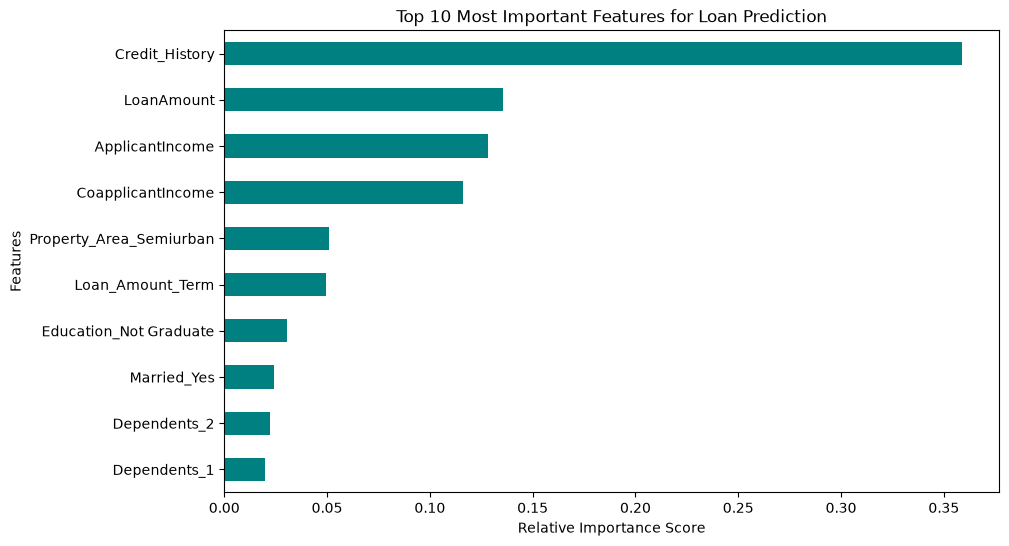

In [8]:
# Cell 6: Plot Feature Importance
feature_importances = pd.Series(rf_model.feature_importances_, index=X.columns)

plt.figure(figsize=(10, 6))
feature_importances.nlargest(10).plot(kind='barh', color='teal')
plt.title("Top 10 Most Important Features for Loan Prediction")
plt.xlabel("Relative Importance Score")
plt.ylabel("Features")
plt.gca().invert_yaxis()
plt.show()